<b>DV Experiment 5: Geo-Visualization with Maps</b><br><br><b>Aim:</b> Plot country-level sales and cases alongside city latitude/longitude coordinates using filled choropleth and symbol maps.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots

In [2]:
data_dir = "datasets" if os.path.exists("datasets") else os.path.join("DV_Lab", "datasets")
out_dir = "outputs" if os.path.exists("outputs") else (os.path.join("DV_Lab", "outputs") if os.path.exists("DV_Lab") else "outputs")
os.makedirs(out_dir, exist_ok=True)

In [3]:
country_df = pd.read_csv(os.path.join(data_dir, "country_geo_data.csv"))
city_df = pd.read_csv(os.path.join(data_dir, "city_geo_data.csv"))

print("Country Geo Summary (Top 8 by Sales):")
print(country_df.sort_values("Sales", ascending=False).head(8).to_string(index=False))

Country Geo Summary (Top 8 by Sales):
       Country ISO_Code        Region  Sales  Profit  Orders  Confirmed_Cases
 United States      USA North America 482500   74200     620        103436829
         India      IND          Asia 365400   61800     510         45035393
         Japan      JPN          Asia 312000   51400     405         33803572
       Germany      DEU        Europe 294100   46900     390         38828995
United Kingdom      GBR        Europe 268700   41200     355         24910387
        France      FRA        Europe 241800   36500     320         40138560
        Canada      CAN North America 215600   35100     290          4946090
   South Korea      KOR          Asia 204900   34200     275         34571873


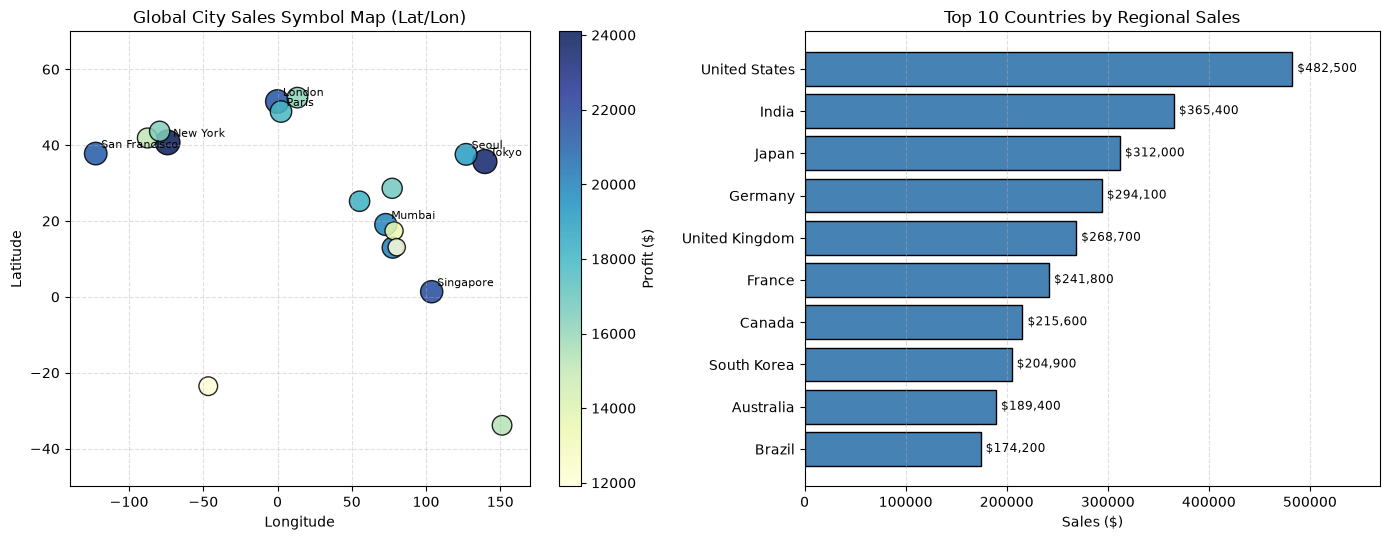

Interactive Geo Map saved to: outputs\DV_Exp5_Geo_Map.html


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

scatter = axes[0].scatter(
    city_df["Longitude"],
    city_df["Latitude"],
    s=city_df["Sales"] / 450.0,
    c=city_df["Profit"],
    cmap="YlGnBu",
    alpha=0.85,
    edgecolor="black",
)
for _, row in city_df.nlargest(8, "Sales").iterrows():
    axes[0].annotate(row["City"], (row["Longitude"], row["Latitude"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
axes[0].set_title("Global City Sales Symbol Map (Lat/Lon)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_xlim(-140, 170)
axes[0].set_ylim(-50, 70)
axes[0].grid(True, linestyle="--", alpha=0.4)
fig.colorbar(scatter, ax=axes[0], label="Profit ($)")

top_countries = country_df.sort_values("Sales", ascending=True).tail(10)
axes[1].barh(top_countries["Country"], top_countries["Sales"], color="steelblue", edgecolor="black")
for i, val in enumerate(top_countries["Sales"]):
    axes[1].text(val + 5000, i, f"${val:,.0f}", va="center", fontsize=8.5)
axes[1].set_xlim(0, top_countries["Sales"].max() * 1.18)
axes[1].set_title("Top 10 Countries by Regional Sales")
axes[1].set_xlabel("Sales ($)")
axes[1].grid(True, axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

choro_fig = px.choropleth(
    country_df,
    locations="ISO_Code",
    color="Sales",
    hover_name="Country",
    hover_data={"Profit": ":,.0f", "Orders": True, "Confirmed_Cases": ":,.0f"},
    color_continuous_scale="Blues",
    title="Filled Geo Map: Country-Wise Sales & Confirmed Cases",
)

bubble_fig = px.scatter_geo(
    city_df,
    lat="Latitude",
    lon="Longitude",
    size="Sales",
    color="Country",
    hover_name="City",
    hover_data={"Sales": ":,.0f", "Profit": ":,.0f", "Active_Stores": True},
    projection="natural earth",
    title="Symbol Geo Map: City-Wise Sales Distribution",
)

geo_combined = make_subplots(
    rows=2,
    cols=1,
    specs=[[{"type": "choropleth"}], [{"type": "scattergeo"}]],
    subplot_titles=("Filled Choropleth Map (Country Sales)", "Symbol Map (City Sales)"),
    vertical_spacing=0.06,
)

for trace in choro_fig.data:
    geo_combined.add_trace(trace, row=1, col=1)
for trace in bubble_fig.data:
    geo_combined.add_trace(trace, row=2, col=1)

geo_combined.update_geos(showcountries=True, countrycolor="lightgray", projection_type="natural earth")
geo_combined.update_layout(height=950, width=1100, title_text="Geo-Visualization: Filled Map & Symbol Map")

html_path = os.path.join(out_dir, "DV_Exp5_Geo_Map.html")
geo_combined.write_html(html_path, include_plotlyjs="cdn")
print("Interactive Geo Map saved to:", html_path)

<b>Observation:</b> Filled choropleths distinguish top national markets while symbol bubbles pinpoint city-level retail demand.